# Ground-plane cheesing, native QDesign geometry

Demo of `GroundPlaneCheese`: a triangular (hex-packed) lattice of circular
holes (each hole an N-gon, capped at 16 sides to bound per-hole mesh growth),
cut directly out of a `QDesign`'s ground plane -- no `.gds` export/import, no
`gdsfactory`, no `QGDSRenderer`. This replaces the `fill`/`fill_tiled`
GDS-based approach this directory (`vortex_trap_fill_workflow.py`) originally
tried: SQDMetal rebuilds geometry straight from the QDesign's own shapely
polygons, and a gdsfactory-cheesed GDS has no clean path back into that.

Design used: the `josephson_array_resonator` bare-JJ-array build (copied into
this directory as `build_design.py`) -- a single custom component
(`JosephsonArray`) sitting in an auto-sized chip, so it's a clean small
example of an existing component the cheese pattern must keep clear of via
`keepout_margin`.

`GroundPlaneCheese` itself lives in `ground_plane_cheese.py` next to this
notebook (not yet installed into the `qcg-quantum-design` env's
`qiskit_metal/qlibrary/sample_shapes/`, which is where this repo's other
custom qlibrary components live -- ask before copying it there).


In [1]:
import sys
sys.path.insert(0, '.')

import qmview
from build_design import build_design
from ground_plane_cheese import GroundPlaneCheese


## Build the base design (no cheesing yet)

In [2]:
design = build_design(n_junctions=40)

n_metal_nets, min_gap_um, n_ground_pieces = qmview.sanity_checks(design)
print(f"chip size: {design.chips.main.size.size_x} x {design.chips.main.size.size_y}")


metal nets (>300 um2): 0   min gap between them: inf um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]
chip size: 1.034mm x 0.706mm


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'before cheesing'}, xlabel='x (mm)', ylabel='y (mm)'>)

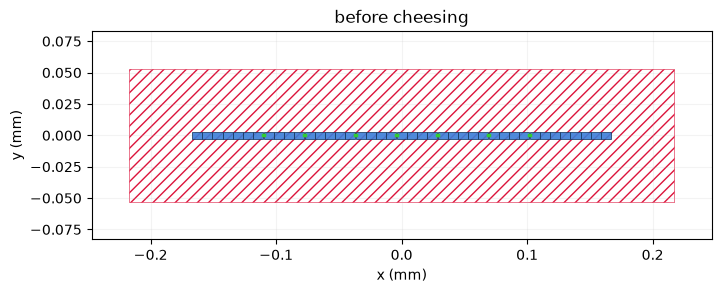

In [3]:
qmview.preview(design, title="before cheesing")


## Apply the cheese

Cheese the whole chip footprint. `keepout_margin` reads whatever non-subtract
(metal) geometry already exists in the design at this point (the
`JosephsonArray` islands) and drops any hole whose center would land within
`keepout_margin + hole_radius` of it -- add this component *last*, after
every component it must stay clear of.

`GroundPlaneCheese.make()` prints the hole count / coverage / mesh-element
proxy itself, and raises `RuntimeError` if the result isn't a single
connected ground plane -- opt-in cheesing that fails loudly rather than
silently handing a fragmented plane downstream.

In [26]:
ENABLE_CHEESE = True  # opt-in flag -- everything above is unchanged/identical when False

if ENABLE_CHEESE:
    chip_size = design.chips.main.size
    cheese = GroundPlaneCheese(design, 'ground_cheese', options=dict(
        pos_x=chip_size.center_x,
        pos_y=chip_size.center_y,
        width=chip_size.size_x,
        height=chip_size.size_y,
        pitch='60um',
        hole_radius='15um',
        n_sides='12',
        keepout_margin='56um',
    ))
    print(cheese.cheese_report)


GroundPlaneCheese 'ground_cheese': 270 holes, coverage=0.250, mesh element proxy (n_holes * n_sides)=3240
{'n_holes': 270, 'coverage': 0.24965208160503238, 'mesh_element_proxy': 3240}


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'after cheesing'}, xlabel='x (mm)', ylabel='y (mm)'>)

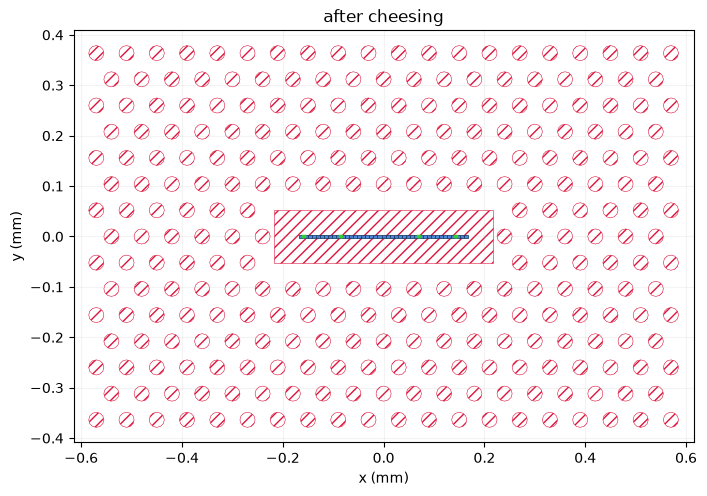

In [27]:
qmview.preview(design, title="after cheesing")


In [28]:
n_metal_nets, min_gap_um, n_ground_pieces = qmview.sanity_checks(design)
assert n_ground_pieces == 1, "ground plane fragmented -- GroundPlaneCheese.make() should have already raised on this"
print("cheese report:", cheese.cheese_report)


metal nets (>300 um2): 0   min gap between them: inf um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]
cheese report: {'n_holes': 270, 'coverage': 0.24965208160503238, 'mesh_element_proxy': 3240}
